# Exploring the token IMAGES

Exploratory analysis of the images attached to pump.fun tokens, collected by Phase C of
`pumpfun-crawler` (`collect_metadata.py --stage images`).

**Data model** (see the crawler README, *Storage model* / *Data schemas*):

```
tokens (mint) ──1 token_metadata (mint)  ── image_url
             └──1 token_images  (mint)  ── sha256 ──> images/shard_*.parquet (sha256, bytes)
```

- `parquet/token_images/token_images_YYYY-MM-DD.parquet` is the **ledger**: one row per mint with
  the fetch status, source format/dimensions/size, and the `sha256` + `shard` of the stored blob.
- `images/shard_NNNNNN.parquet` holds the **bytes**: a 384px-max WebP (frame 0 only for
  animations), content-addressed by `sha256`, so artwork reused by many tokens is stored once.

Everything heavy is done in DuckDB straight over the Parquet files; only aggregates and small
samples of image bytes are pulled into memory.

## Setup

In [1]:
from concurrent.futures import ProcessPoolExecutor
import io
import os
from pathlib import Path
import warnings

import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import numpy as np
import pandas as pd
from PIL import Image

from crypto_analysis.image_features import hamming_neighbors, shard_features, star_clusters
from crypto_analysis.plotting import (
    COLORS,
    FIG_4x3,
    FIG_6x4,
    format_date_axis,
    plain_caption,
    plain_text,
    mark_events,
    save_figure,
    set_latex_style,
    tex_escape,
)

USE_TEX = set_latex_style()  # real LaTeX if installed, Computer Modern mathtext otherwise
print("Real LaTeX rendering:", USE_TEX)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
# Token names use many scripts/emoji the default font lacks; the tiles still render.
warnings.filterwarnings("ignore", message="Glyph .* missing from font")

Real LaTeX rendering: False


In [3]:
DATA_DIR = Path("/home/datalake/pumpfun/data")
PARQUET_DIR = DATA_DIR / "parquet"
IMAGES_DIR = DATA_DIR / "images"

FIG_DIR = Path("../reports/figures")
SAVE_FIGS = True  # set True to write every figure to FIG_DIR as PDF (for LaTeX) + PNG

SEED = 42
rng = np.random.default_rng(SEED)

con = duckdb.connect()
con.execute("SET threads TO 16")

In [4]:
# Views over the Parquet globs. `day` is the partition date taken from the file name.
con.execute(rf'''
CREATE OR REPLACE VIEW token_images AS
SELECT *, CAST(regexp_extract(filename, '(\d{{4}}-\d{{2}}-\d{{2}})', 1) AS DATE) AS day
FROM read_parquet('{PARQUET_DIR}/token_images/*.parquet', filename = true)
''')
con.execute(f'''
CREATE OR REPLACE VIEW tokens AS
SELECT * FROM read_parquet('{PARQUET_DIR}/tokens/*.parquet')
''')
con.execute(f'''
CREATE OR REPLACE VIEW token_metadata AS
SELECT mint, meta_name, meta_symbol, description
FROM read_parquet('{PARQUET_DIR}/token_metadata/*.parquet')
''')
con.execute(f'''
CREATE OR REPLACE VIEW graduations AS
SELECT * FROM read_parquet('{PARQUET_DIR}/graduations/*.parquet')
''')
con.execute(f'''
CREATE OR REPLACE VIEW blobs AS
SELECT * FROM read_parquet('{IMAGES_DIR}/shard_*.parquet')
''')

def q(sql, **params):
    '''Run SQL and return a DataFrame.'''
    return con.execute(sql, params or None).df()

### Plot and image helpers

`load_images` reads only the requested blobs: it groups the wanted hashes by shard and asks DuckDB
for those rows of each shard file, so showing 30 images never scans the 40 GB of shards.

In [5]:
BLUE, ORANGE, AQUA = COLORS["blue"], COLORS["orange"], COLORS["aqua"]
INK, INK_2, GRID = COLORS["ink"], COLORS["ink_secondary"], COLORS["grid"]

thousands = FuncFormatter(lambda x, _: tex_escape(f"{x:,.0f}"))


def pct(v, decimals=1):
    '''Percentage label that is safe under real LaTeX.'''
    return tex_escape(f"{v:.{decimals}%}")


def save(fig, name):
    if SAVE_FIGS:
        save_figure(fig, FIG_DIR / f"images_{name}")


def load_images(shas):
    '''Return {sha256: PIL.Image} for the given hashes, reading only the shards that hold them.'''
    shas = pd.DataFrame({"sha256": pd.unique(pd.Series(list(shas)))})
    con.register("wanted", shas)
    locs = q('''
        SELECT DISTINCT w.sha256, i.shard
        FROM wanted w JOIN token_images i USING (sha256)
        WHERE i.status = 'ok'
    ''')
    out = {}
    for shard, grp in locs.groupby("shard"):
        con.register("wanted_shard", grp[["sha256"]])
        rows = q(f'''
            SELECT b.sha256, b.bytes
            FROM read_parquet('{IMAGES_DIR / shard}') b
            JOIN wanted_shard USING (sha256)
        ''')
        for sha, raw in zip(rows.sha256, rows.bytes):
            out[sha] = Image.open(io.BytesIO(raw))
    con.unregister("wanted")
    return out


def names_for(shas):
    '''{sha256: most common meta_name among the tokens using that image}.'''
    con.register("name_shas", pd.DataFrame({"sha256": pd.unique(pd.Series(list(shas)))}))
    names = q('''
        SELECT i.sha256, mode(m.meta_name) AS name
        FROM token_images i
        JOIN name_shas USING (sha256)
        LEFT JOIN token_metadata m USING (mint)
        WHERE i.status = 'ok'
        GROUP BY 1
    ''')
    con.unregister("name_shas")
    return dict(zip(names.sha256, names.name.fillna("")))


def show_grid(shas, titles=None, ncols=8, size=1.8, suptitle=None):
    '''Plot images in a grid; `titles` is an optional list of captions aligned with `shas`.
    A `None` sha leaves its tile blank (useful to keep one group per row).

    Image grids are exempt from the 4x3 / 6x4 rule (their shape follows the number of tiles), and
    they render without LaTeX because captions hold arbitrary token names.
    '''
    with plain_text():
        return _show_grid(shas, titles, ncols, size, suptitle)


def _show_grid(shas, titles, ncols, size, suptitle):
    shas = list(shas)
    titles = None if titles is None else list(titles)
    imgs = load_images([sha for sha in shas if sha is not None])
    nrows = int(np.ceil(len(shas) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + 0.35)))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[len(shas):]:
        ax.axis("off")
    for k, sha in enumerate(shas):
        ax = axes[k]
        if sha is None:
            ax.axis("off")
            continue
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():  # thin frame so white/blank artwork stays visible
            spine.set_visible(True)
            spine.set_color(GRID)
        if sha in imgs:
            ax.imshow(imgs[sha].convert("RGB"))
        if titles is not None:
            ax.set_title(plain_caption(str(titles[k])[:22]), fontsize=7.5, fontweight="normal",
                         loc="center", color=INK_2)
    if suptitle:
        fig.suptitle(suptitle, color=INK)
    return fig

## 1. Collection coverage

How many tokens have an image ledger row, how many fetches succeeded, and how that evolves day by day.
Remember the README's rule: **absence from `token_images` means "not attempted"**, a failed fetch
still writes a row with its `status`.

In [6]:
overview = q('''
SELECT
    (SELECT count(*) FROM tokens)                                  AS tokens,
    count(*)                                                       AS ledger_rows,
    count(DISTINCT mint)                                           AS ledger_mints,
    count(*) FILTER (WHERE status = 'ok')                          AS images_ok,
    count(DISTINCT sha256) FILTER (WHERE status = 'ok')            AS distinct_images,
    min(day)                                                       AS first_day,
    max(day)                                                       AS last_day
FROM token_images
''').T.rename(columns={0: "value"})
overview

,value
tokens,6569510
ledger_rows,5213844
ledger_mints,5213844
images_ok,5141193
distinct_images,2695112
first_day,2025-10-26 00:00:00
last_day,2026-07-10 00:00:00


In [7]:
status = q('''
SELECT status, count(*) AS n
FROM token_images GROUP BY 1 ORDER BY n DESC
''')
status["share"] = (status.n / status.n.sum()).map("{:.2%}".format)
status

,status,n,share
0,ok,5141193,98.61%
1,http_error,56423,1.08%
2,decode_error,12784,0.25%
3,timeout,1809,0.03%
4,too_large,719,0.01%
5,no_url,534,0.01%
6,unsupported,382,0.01%


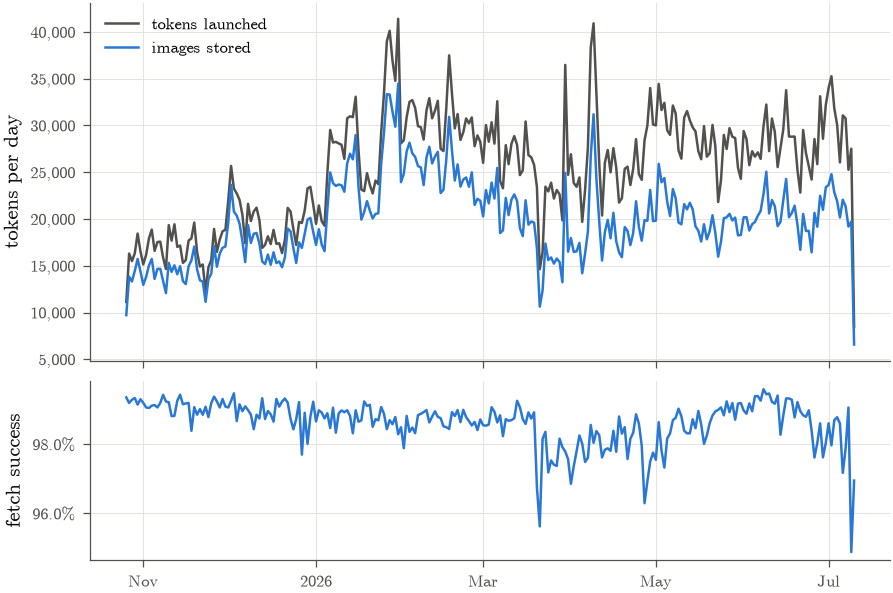

In [8]:
daily = q('''
WITH t AS (
    SELECT CAST(to_timestamp(created_at) AS DATE) AS day, count(*) AS tokens
    FROM tokens GROUP BY 1
), i AS (
    SELECT day, count(*) AS attempted, count(*) FILTER (WHERE status = 'ok') AS ok
    FROM token_images GROUP BY 1
)
SELECT t.day, t.tokens, coalesce(i.attempted, 0) AS attempted, coalesce(i.ok, 0) AS ok
FROM t LEFT JOIN i USING (day)
ORDER BY day
''')
daily["day"] = pd.to_datetime(daily.day)
daily["success_rate"] = daily.ok / daily.attempted

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=FIG_6x4, sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(daily.day, daily.tokens, color=INK_2, label="tokens launched")
ax1.plot(daily.day, daily.ok, color=BLUE, label="images stored")
ax1.yaxis.set_major_formatter(thousands)
ax1.set_ylabel("tokens per day")
ax1.legend(loc="upper left")
ax2.plot(daily.day, daily.success_rate, color=BLUE)
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_ylabel("fetch success")
format_date_axis(ax2)
save(fig, "coverage_daily")

In [9]:
# Which hosts fail? Failure statuses broken down by the image URL's host.
q('''
SELECT regexp_extract(image_url, '^https?://([^/]+)', 1) AS host,
       status, count(*) AS n
FROM token_images
WHERE status <> 'ok'
GROUP BY 1, 2 ORDER BY n DESC LIMIT 15
''')

,host,status,n
0,image.solanatracker.io,http_error,14847
1,ipfs.io,decode_error,11070
2,pbs.twimg.com,http_error,10760
3,storage.googleapis.com,http_error,8191
4,ipfs.launchblitz.ai,http_error,4996
5,replicate.delivery,http_error,4476
6,metadata.j7tracker.io,http_error,1726
7,edge.uxento.io,http_error,1421
8,twproxy.twproxy.workers.dev,http_error,1362
9,im.runware.ai,http_error,988


## 2. Source image properties

These describe the **original** file as uploaded by the token creator (before the crawler's resize to
384px WebP). Restricted to `status = 'ok'`.

In [10]:
fmt = q('''
SELECT orig_format, count(*) AS n,
       count(*) FILTER (WHERE is_animated) AS animated,
       median(orig_bytes) AS median_bytes
FROM token_images WHERE status = 'ok'
GROUP BY 1 ORDER BY n DESC
''')
fmt["share"] = fmt.n / fmt.n.sum()
fmt.style.format({"n": "{:,}", "animated": "{:,}", "median_bytes": "{:,.0f}", "share": "{:.2%}"})

,orig_format,n,animated,median_bytes,share
0,JPEG,"2,470,671",0,"43,951",48.06%
1,PNG,"1,734,316",14,"352,288",33.73%
2,WEBP,"885,858","2,611","13,324",17.23%
3,GIF,"43,701","37,510","832,966",0.85%
4,AVIF,"4,511",6,"15,090",0.09%
5,MPO,"1,631","1,631","2,275,816",0.03%
6,nan,439,0,"4,492,069",0.01%
7,HEIF,31,0,"4,468,859",0.00%
8,ICO,29,0,"90,638",0.00%
9,BMP,6,0,"479,812",0.00%


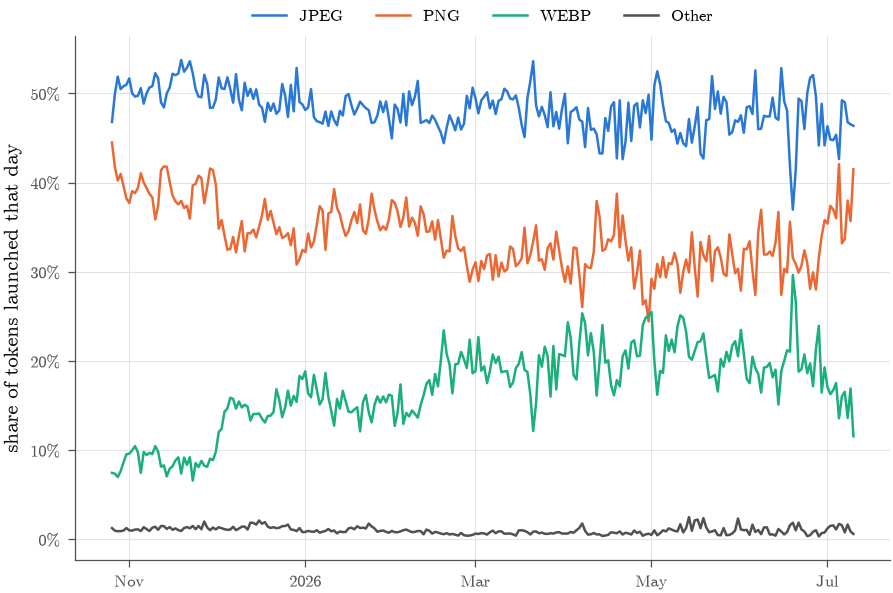

In [11]:
fmt_daily = q('''
SELECT day, orig_format, count(*) AS n
FROM token_images WHERE status = 'ok' AND orig_format IS NOT NULL
GROUP BY 1, 2
''')
fmt_daily = fmt_daily.pivot(index="day", columns="orig_format", values="n").fillna(0)
fmt_share = fmt_daily.div(fmt_daily.sum(axis=1), axis=0)
top3 = fmt.orig_format.dropna().head(3).tolist()
fmt_share = fmt_share[top3].assign(Other=1 - fmt_share[top3].sum(axis=1))

fig, ax = plt.subplots(figsize=FIG_6x4)
for col, color in zip(fmt_share.columns, [BLUE, ORANGE, AQUA, INK_2]):
    ax.plot(pd.to_datetime(fmt_share.index), fmt_share[col], color=color, label=col)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("share of tokens launched that day")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.08))
format_date_axis(ax)
save(fig, "format_share_daily")

In [12]:
dims = q('''
SELECT orig_width, orig_height, orig_bytes, stored_bytes, is_animated, n_frames
FROM token_images WHERE status = 'ok' AND orig_width IS NOT NULL
USING SAMPLE 500000 ROWS (reservoir, 42)
''')
dims["aspect"] = dims.orig_width / dims.orig_height
dims["long_side"] = dims[["orig_width", "orig_height"]].max(axis=1)

print("Most common source resolutions (from a 500k sample):")
display((dims.orig_width.astype(str) + "x" + dims.orig_height.astype(str))
        .value_counts(normalize=True).head(12).map("{:.2%}".format).to_frame("share"))
print(f"Square images: {(dims.aspect == 1).mean():.1%}")
print(f"Animated sources: {dims.is_animated.mean():.2%}")

Most common source resolutions (from a 500k sample):


,share
512x512,8.12%
400x400,7.59%
1024x1024,6.99%
500x500,3.92%
1254x1254,1.68%
128x128,1.50%
600x600,1.48%
256x256,1.40%
200x200,1.37%
320x320,1.01%


Square images: 53.6%
Animated sources: 0.81%


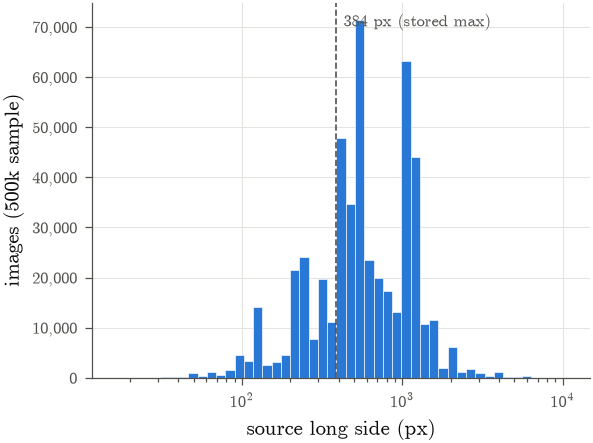

In [13]:
# One 4x3 figure per property, so each can be a LaTeX subfigure.
fig, ax = plt.subplots(figsize=FIG_4x3)
bins = np.logspace(np.log10(16), np.log10(dims.long_side.max()), 50)
ax.hist(dims.long_side, bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.axvline(384, color=INK_2, ls="--", lw=0.8)
ax.text(384 * 1.12, ax.get_ylim()[1] * 0.97, "384 px (stored max)", color=INK_2, fontsize=8, va="top")
ax.set_xlabel("source long side (px)")
ax.set_ylabel("images (500k sample)")
ax.yaxis.set_major_formatter(thousands)
save(fig, "source_long_side")

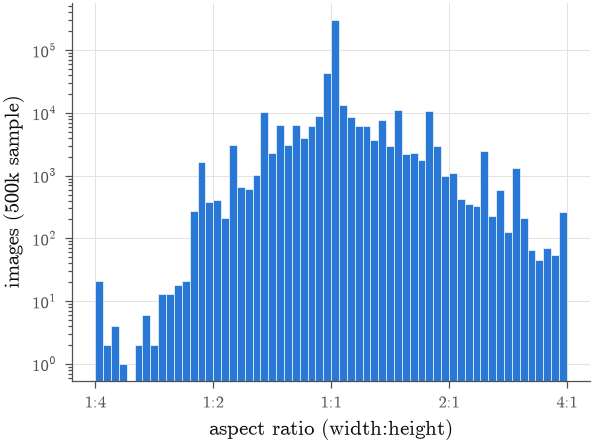

In [14]:
fig, ax = plt.subplots(figsize=FIG_4x3)
ax.hist(np.log2(dims.aspect.clip(1 / 4, 4)), bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xticks([-2, -1, 0, 1, 2], ["1:4", "1:2", "1:1", "2:1", "4:1"])
ax.set_yscale("log")
ax.set_xlabel("aspect ratio (width:height)")
ax.set_ylabel("images (500k sample)")
save(fig, "source_aspect_ratio")

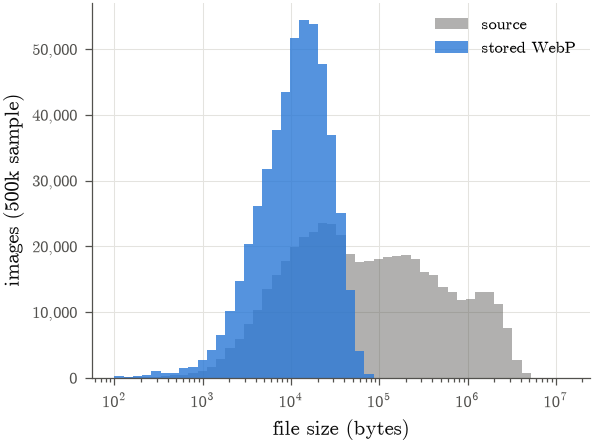

In [15]:
fig, ax = plt.subplots(figsize=FIG_4x3)
bins = np.logspace(2, np.log10(dims.orig_bytes.max()), 50)
ax.hist(dims.orig_bytes, bins=bins, color=INK_2, alpha=0.45, label="source")
ax.hist(dims.stored_bytes, bins=bins, color=BLUE, alpha=0.8, label="stored WebP")
ax.set_xscale("log")
ax.set_xlabel("file size (bytes)")
ax.set_ylabel("images (500k sample)")
ax.yaxis.set_major_formatter(thousands)
ax.legend()
save(fig, "source_file_size")

## 3. Image reuse

Because blobs are content-addressed, `sha256` lets us count how many tokens share **byte-identical**
stored artwork (the crawler re-encodes everything identically, so the same source file → same hash).
Reuse is a strong signal for copycat / templated launches and for bot-driven token farms.

In [16]:
reuse = q('''
SELECT sha256, count(*) AS n_tokens, min(day) AS first_day, max(day) AS last_day,
       count(DISTINCT day) AS n_days
FROM token_images WHERE status = 'ok'
GROUP BY 1
''')
n_tok = reuse.n_tokens.sum()
summary = pd.Series({
    "tokens with an image": n_tok,
    "distinct images": len(reuse),
    "images used by exactly 1 token": (reuse.n_tokens == 1).sum(),
    "tokens whose image is shared with >=1 other token": reuse.loc[reuse.n_tokens > 1, "n_tokens"].sum(),
    "tokens sharing an image with >100 others": reuse.loc[reuse.n_tokens > 100, "n_tokens"].sum(),
})
display(summary.map("{:,}".format).to_frame("count"))
print(f"Share of tokens with a non-unique image: {summary.iloc[3] / n_tok:.1%}")

,count
tokens with an image,"5,141,193"
distinct images,"2,695,112"
images used by exactly 1 token,"2,090,668"
tokens whose image is shared with >=1 other token,"3,050,525"
tokens sharing an image with >100 others,"357,903"


Share of tokens with a non-unique image: 59.3%


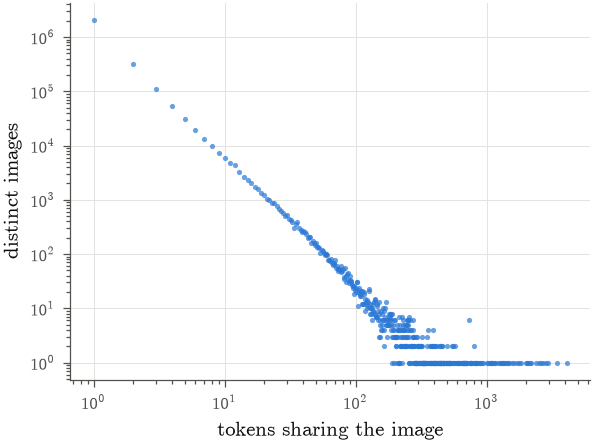

In [17]:
fig, ax = plt.subplots(figsize=FIG_4x3)
counts = reuse.n_tokens.value_counts().sort_index()
ax.loglog(counts.index, counts.values, "o", ms=2.5, color=BLUE, alpha=0.7, markeredgewidth=0)
ax.set_xlabel("tokens sharing the image")
ax.set_ylabel("distinct images")
save(fig, "reuse_distribution")

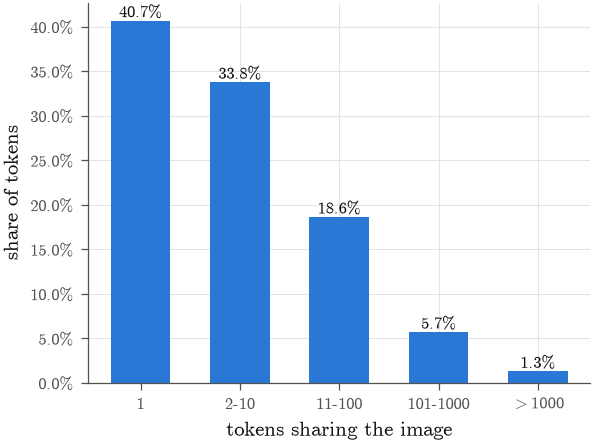

In [18]:
fig, ax = plt.subplots(figsize=FIG_4x3)
buckets = pd.cut(reuse.n_tokens, [0, 1, 10, 100, 1000, np.inf],
                 labels=["1", "2-10", "11-100", "101-1000", ">1000"])
tok_by_bucket = reuse.groupby(buckets, observed=False).n_tokens.sum() / n_tok
ax.bar([tex_escape(b) for b in tok_by_bucket.index.astype(str)], tok_by_bucket.values,
       color=BLUE, width=0.6)
for x, v in enumerate(tok_by_bucket.values):
    ax.text(x, v, pct(v), ha="center", va="bottom", fontsize=8, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("tokens sharing the image")
ax.set_ylabel("share of tokens")
save(fig, "reuse_buckets")

### The most reused images

Each tile shows how many tokens use it and the most common `meta_name` among those tokens.

,n_tokens,n_names,top_name,first_day,last_day,n_days
0,4102,77,KILLME,2026-04-10,2026-07-05,39
1,3436,5,MAYHEM,2026-05-02,2026-07-07,32
2,2959,3,Agent Smith,2026-05-10,2026-06-17,25
3,2838,6,banana dad,2026-05-30,2026-07-09,18
4,2706,3,50,2026-06-08,2026-07-09,18
5,2604,1434,9,2025-11-12,2026-07-05,77
6,2513,1,METH DAMON,2026-06-07,2026-06-30,12
7,2378,865,NOTHING,2025-10-26,2026-07-09,234
8,2180,287,whats inside that house,2026-02-15,2026-06-25,23
9,2142,5,Rocket,2026-05-03,2026-06-20,31


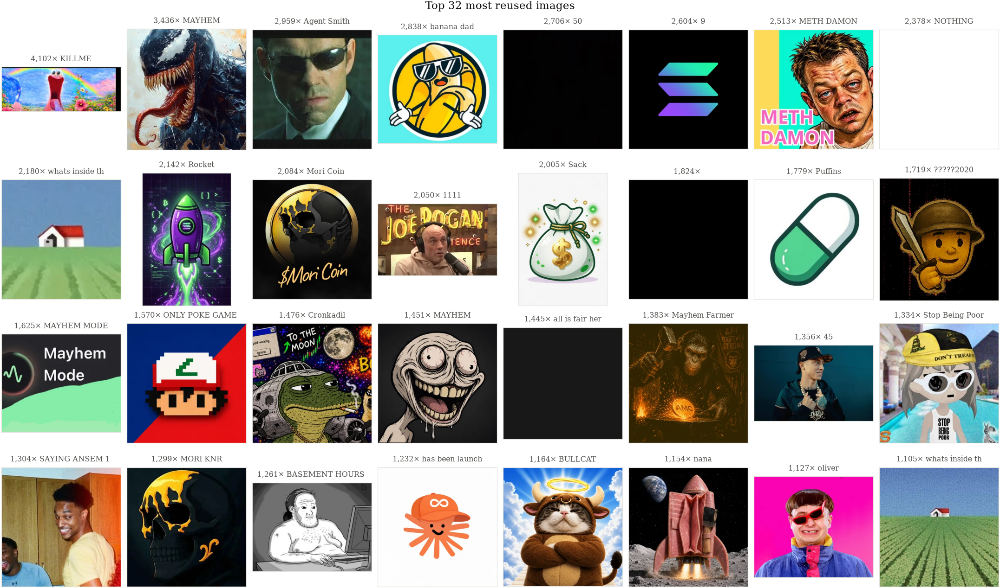

In [19]:
TOP_K = 32
top = reuse.nlargest(TOP_K, "n_tokens").reset_index(drop=True)
con.register("top_shas", top[["sha256"]])
top_names = q('''
SELECT i.sha256, mode(m.meta_name) AS top_name, count(DISTINCT m.meta_name) AS n_names
FROM token_images i
JOIN top_shas USING (sha256)
LEFT JOIN token_metadata m USING (mint)
GROUP BY 1
''')
top = top.merge(top_names, on="sha256", how="left")
display(top[["n_tokens", "n_names", "top_name", "first_day", "last_day", "n_days"]].head(15))

fig = show_grid(top.sha256, [f"{n:,}× {name}" for n, name in zip(top.n_tokens, top.top_name)],
                suptitle=f"Top {TOP_K} most reused images")
save(fig, "top_reused")

## 4. Copycats, graduations and checkpoints over time

Every token is placed relative to the **first** token that used its image (ordered by
`tokens.created_at`):

- **original**: the first token to use the image.
- **copy**: a later token with the same `sha256`.
- **self-relaunch**: a copy launched by the same `coin_creator` as the original (one creator
  recycling their own artwork, typical of bot farms).
- **copy of a graduate**: a copy launched *after* a token with that image graduated (chasing a
  winner).

A token *graduates* when its bonding curve completes (`graduations` table).

In [20]:
con.execute('''
CREATE OR REPLACE TEMP TABLE token_flags AS
WITH base AS (
    SELECT i.mint, i.sha256, i.day, t.created_at, t.coin_creator, g.block_time AS grad_time
    FROM token_images i
    JOIN tokens t USING (mint)
    LEFT JOIN graduations g USING (mint)
    WHERE i.status = 'ok'
), first_use AS (
    SELECT sha256, count(*) AS n_tokens, min(created_at) AS first_created,
           arg_min(coin_creator, created_at) AS first_creator
    FROM base GROUP BY 1
), first_grad AS (
    SELECT sha256, min(grad_time) AS first_grad FROM base WHERE grad_time IS NOT NULL GROUP BY 1
)
SELECT b.*, f.n_tokens,
       b.grad_time IS NOT NULL                                   AS graduated,
       b.created_at > f.first_created                            AS is_copy,
       b.created_at > f.first_created
           AND b.coin_creator = f.first_creator                  AS is_self_relaunch,
       coalesce(b.created_at > g.first_grad, false)              AS copies_graduate,
       b.created_at - g.first_grad                               AS secs_after_graduation
FROM base b
JOIN first_use f USING (sha256)
LEFT JOIN first_grad g USING (sha256)
''')

roles = q('''
SELECT count(*)                                  AS tokens,
       count(*) FILTER (WHERE NOT is_copy)       AS originals,
       count(*) FILTER (WHERE is_copy)           AS copies,
       count(*) FILTER (WHERE is_self_relaunch)  AS self_relaunches,
       count(*) FILTER (WHERE copies_graduate)   AS copies_of_a_graduate,
       count(*) FILTER (WHERE graduated)         AS graduated
FROM token_flags
''').T.rename(columns={0: "count"})
roles["share"] = (roles["count"] / roles.loc["tokens", "count"]).map("{:.1%}".format)
roles

,count,share
tokens,5141193,100.0%
originals,2737768,53.3%
copies,2403425,46.7%
self_relaunches,936015,18.2%
copies_of_a_graduate,227397,4.4%
graduated,53251,1.0%


### Copies of graduated tokens

How fast do copycats show up after a token graduates, and which graduates attracted the most copies?

Hours from the graduation to the copy, quantiles:


,hours
0.10,0.07
0.25,0.42
0.50,13.71
0.75,189.65
0.90,1097.51


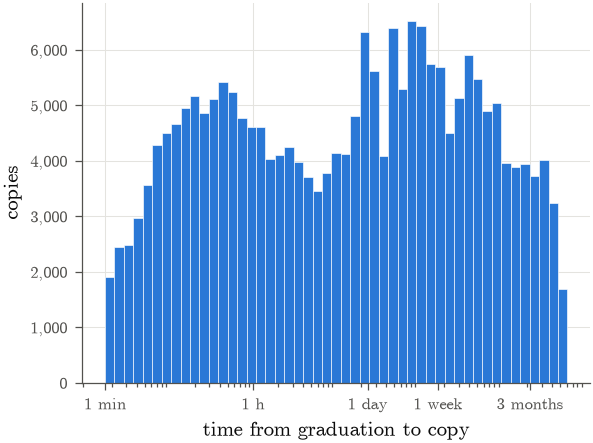

In [21]:
delay_h = q("SELECT secs_after_graduation / 3600.0 AS h FROM token_flags WHERE copies_graduate").h
print("Hours from the graduation to the copy, quantiles:")
display(delay_h.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_frame("hours"))

fig, ax = plt.subplots(figsize=FIG_4x3)
bins = np.logspace(np.log10(1 / 60), np.log10(delay_h.max()), 50)
ax.hist(delay_h, bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.set_xticks([1 / 60, 1, 24, 24 * 7, 24 * 90], ["1 min", "1 h", "1 day", "1 week", "3 months"])
ax.set_xlabel("time from graduation to copy")
ax.set_ylabel("copies")
ax.yaxis.set_major_formatter(thousands)
save(fig, "copy_delay_after_graduation")

,name,graduated_on,n_copies
0,KILLME,2026-04-17,3206
1,50,2026-06-08,2704
2,banana dad,2026-05-30,2699
3,METH DAMON,2026-06-07,2504
4,NOTHING,2025-11-11,2330
5,MAYHEM,2026-06-11,1949
6,,2025-10-31,1809
7,1111,2026-06-05,1730
8,Puffins,2026-01-16,1601
9,ONLY POKE GAME SHILLED BY SOLANA,2026-06-20,1569


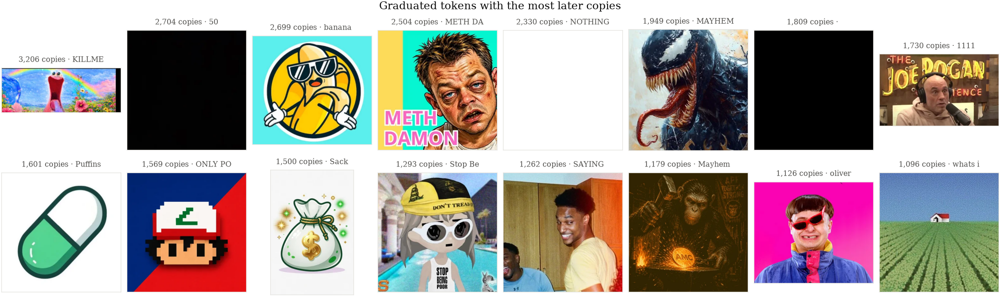

In [22]:
copied = q('''
SELECT sha256, count(*) FILTER (WHERE copies_graduate) AS n_copies,
       CAST(to_timestamp(min(grad_time)) AS DATE) AS graduated_on
FROM token_flags
GROUP BY 1 HAVING n_copies > 0
ORDER BY n_copies DESC
''')
top_copied = copied.head(16).copy()
top_copied["name"] = top_copied.sha256.map(names_for(top_copied.sha256))
display(top_copied[["name", "graduated_on", "n_copies"]])

fig = show_grid(top_copied.sha256, [f"{n:,} copies · {name}" for n, name in
                                     zip(top_copied.n_copies, top_copied.name)],
                suptitle="Graduated tokens with the most later copies")
save(fig, "most_copied_graduates")

### Checkpoints

Dates worth marking on every time series, derived from the data (codes are numbered in
chronological order within each kind):

| code | kind | how it is chosen |
|---|---|---|
| **W** | copycat wave | the images with the most launches in a single day (date = that day) |
| **C** | copied graduate | the graduated tokens with the most later copies (date = graduation day) |
| **S** | graduation spike | days with the most graduations, at least a week apart |
| **R** | reuse regime shift | the day where the 14-day mean share of copies changes the most |
| **E** | external event | anything you know from outside the data: add it to `MANUAL_EVENTS` |

In [23]:
N_PER_KIND = 4
MANUAL_EVENTS = [
    # ("2026-01-01", "short description of something that happened"),
]

events = []

# W: copycat waves
waves = q(f'''
WITH d AS (SELECT sha256, day, count(*) AS n FROM token_flags GROUP BY 1, 2)
SELECT sha256, arg_max(day, n) AS date, max(n) AS peak_n, CAST(sum(n) AS BIGINT) AS total
FROM d GROUP BY 1 ORDER BY peak_n DESC LIMIT {N_PER_KIND}
''')
wave_names = names_for(waves.sha256)
for r in waves.itertuples():
    events.append(("W", r.date, f"copycat wave: '{wave_names[r.sha256]}', {r.peak_n:,} launches that day "
                                f"({r.total:,} in total)"))

# C: most copied graduates
for r in top_copied.head(N_PER_KIND).itertuples():
    events.append(("C", r.graduated_on, f"graduation of '{r.name}', copied by {r.n_copies:,} later tokens"))

# S: graduation spikes, at least 7 days apart
grad_daily = q('''
SELECT CAST(to_timestamp(block_time) AS DATE) AS day, count(*) AS graduations
FROM graduations GROUP BY 1 ORDER BY 1
''')
grad_daily["day"] = pd.to_datetime(grad_daily.day)
grad_daily = grad_daily[grad_daily.day < grad_daily.day.max()]  # the crawl's last day is partial
picked_spikes = []
for r in grad_daily.sort_values("graduations", ascending=False).itertuples():
    if all(abs((r.day - d).days) >= 7 for d in picked_spikes):
        picked_spikes.append(r.day)
        events.append(("S", r.day, f"graduation spike: {r.graduations:,} graduations "
                                   f"(median day: {grad_daily.graduations.median():,.0f})"))
    if len(picked_spikes) == N_PER_KIND:
        break

# R: largest shift of the 14-day mean share of copies
daily_flags = q('''
SELECT day, count(*) AS n,
       avg(CASE WHEN n_tokens > 1 THEN 1 ELSE 0 END) AS shared_any_time,
       avg(is_copy::INT)          AS copied,
       avg(is_self_relaunch::INT) AS self_relaunch,
       avg(copies_graduate::INT)  AS copies_graduate,
       avg(graduated::INT)        AS graduation_rate
FROM token_flags GROUP BY 1 ORDER BY 1
''')
daily_flags["day"] = pd.to_datetime(daily_flags.day)
daily_flags = daily_flags[daily_flags.day < daily_flags.day.max()].reset_index(drop=True)  # partial last day
before = daily_flags.copied.rolling(14).mean()
after = daily_flags.copied[::-1].rolling(14).mean()[::-1].shift(-1)
k = (after - before).abs().idxmax()
events.append(("R", daily_flags.day[k], f"reuse regime shift: share of copies {before[k]:.0%} "
                                        f"(14 days before) → {after[k]:.0%} (14 days after)"))

for date, text in MANUAL_EVENTS:
    events.append(("E", date, text))

checkpoints = pd.DataFrame(events, columns=["kind", "date", "description"])
checkpoints["date"] = pd.to_datetime(checkpoints.date)
checkpoints = checkpoints.sort_values(["kind", "date"])
checkpoints["code"] = checkpoints.kind + (checkpoints.groupby("kind").cumcount() + 1).astype(str)
checkpoints.loc[checkpoints.kind == "R", "code"] = "R"
checkpoints = checkpoints.sort_values("date").reset_index(drop=True)
with pd.option_context("display.max_colwidth", None):
    display(checkpoints[["code", "date", "description"]])

,code,date,description
0,W1,2025-12-03,"copycat wave: 'SPAM', 924 launches that day (925 in total)"
1,W2,2026-01-07,"copycat wave: 'has been launched by Echo', 1,003 launches that day (1,232 in total)"
2,S1,2026-03-12,graduation spike: 656 graduations (median day: 228)
3,S2,2026-03-19,graduation spike: 510 graduations (median day: 228)
4,R,2026-04-06,reuse regime shift: share of copies 45% (14 days before) → 53% (14 days after)
5,C1,2026-04-17,"graduation of 'KILLME', copied by 3,206 later tokens"
6,C2,2026-05-30,"graduation of 'banana dad', copied by 2,699 later tokens"
7,C3,2026-06-07,"graduation of 'METH DAMON', copied by 2,504 later tokens"
8,W3,2026-06-07,"copycat wave: '1111', 1,042 launches that day (2,050 in total)"
9,C4,2026-06-08,"graduation of '50', copied by 2,704 later tokens"


### Time series with checkpoints

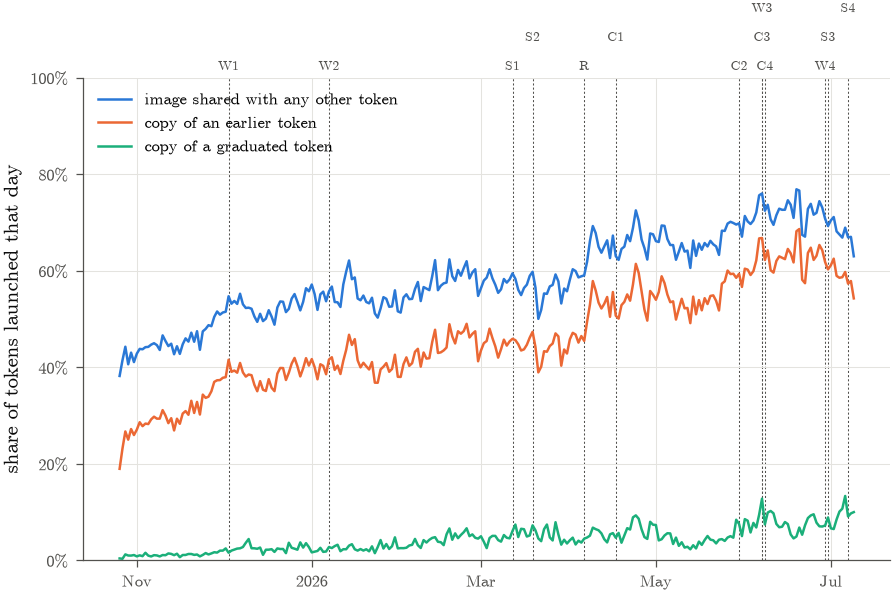

In [24]:
fig, ax = plt.subplots(figsize=FIG_6x4)
ax.plot(daily_flags.day, daily_flags.shared_any_time, color=BLUE, label="image shared with any other token")
ax.plot(daily_flags.day, daily_flags.copied, color=ORANGE, label="copy of an earlier token")
ax.plot(daily_flags.day, daily_flags.copies_graduate, color=AQUA, label="copy of a graduated token")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1)
ax.set_ylabel("share of tokens launched that day")
ax.legend(loc="upper left")
format_date_axis(ax)
mark_events(ax, checkpoints.date, checkpoints.code)
save(fig, "reuse_daily")

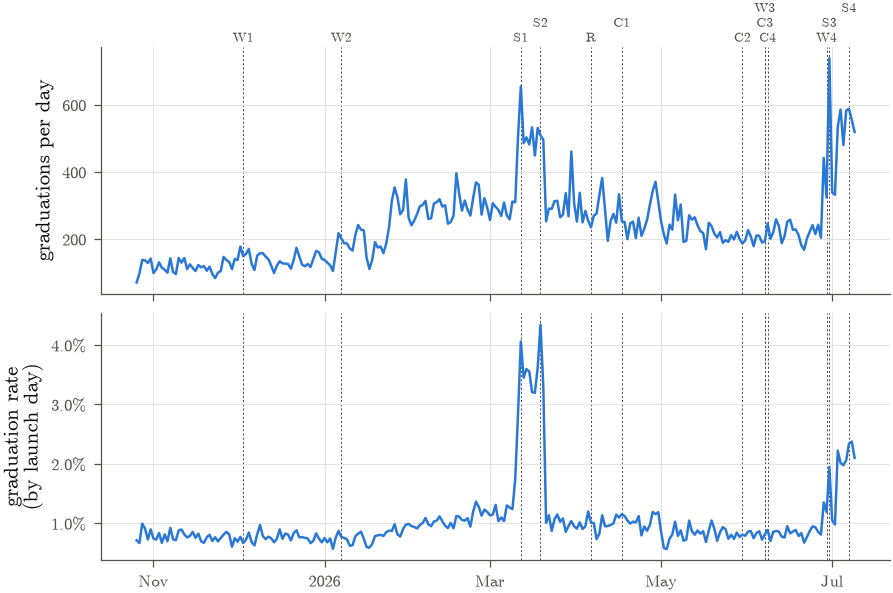

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=FIG_6x4, sharex=True)
ax1.plot(grad_daily.day, grad_daily.graduations, color=BLUE)
ax1.set_ylabel("graduations per day")
ax1.yaxis.set_major_formatter(thousands)
ax2.plot(daily_flags.day, daily_flags.graduation_rate, color=BLUE)
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax2.set_ylabel("graduation rate\n(by launch day)")
format_date_axis(ax2)
mark_events(ax1, checkpoints.date, checkpoints.code)
mark_events(ax2, checkpoints.date, [""] * len(checkpoints))
save(fig, "graduations_daily")

### Graduation rate by image reuse and by role

Graduation counts every graduation in the window, so recent launches had less time to graduate.

In [26]:
grad = q('''
SELECT mint, n_tokens, graduated,
       CASE WHEN NOT is_copy THEN 'original'
            WHEN copies_graduate THEN 'copy of a graduate'
            WHEN is_self_relaunch THEN 'self-relaunch'
            ELSE 'copy (other creator)' END AS role
FROM token_flags
''')
fmt_info = q("SELECT mint, orig_format, is_animated FROM token_images WHERE status = 'ok'")
grad = grad.merge(fmt_info, on="mint", how="left")
grad["reuse_bucket"] = pd.cut(grad.n_tokens, [0, 1, 10, 100, 1000, np.inf],
                              labels=["1 (unique)", "2-10", "11-100", "101-1000", ">1000"])
print(f"Overall graduation rate: {grad.graduated.mean():.2%}")

by_reuse = grad.groupby("reuse_bucket", observed=False).graduated.agg(["mean", "size"])
role_order = ["original", "self-relaunch", "copy (other creator)", "copy of a graduate"]
by_role = grad.groupby("role").graduated.agg(["mean", "size"]).reindex(role_order)
by_fmt = grad.groupby("orig_format").graduated.agg(["mean", "size"]).query("size > 1000")
by_anim = grad.groupby("is_animated").graduated.agg(["mean", "size"])
for table in (by_reuse, by_role, by_fmt.sort_values("mean", ascending=False), by_anim):
    display(table.style.format({"mean": "{:.2%}", "size": "{:,}"}))

Overall graduation rate: 1.04%


,mean,size
reuse_bucket,,
1 (unique),0.91%,"2,090,668"
2-10,1.36%,"1,735,436"
11-100,0.97%,"957,186"
101-1000,0.41%,"292,050"
>1000,0.30%,"65,853"


,mean,size
role,,
original,1.33%,"2,737,768"
self-relaunch,0.41%,"887,901"
copy (other creator),0.65%,"1,288,127"
copy of a graduate,2.05%,"227,397"


,mean,size
orig_format,,
GIF,1.97%,"43,701"
PNG,1.18%,"1,734,316"
JPEG,1.09%,"2,470,671"
MPO,0.98%,"1,631"
AVIF,0.69%,"4,511"
WEBP,0.56%,"885,858"


,mean,size
is_animated,,
False,1.03%,"5,097,247"
True,1.98%,"41,772"


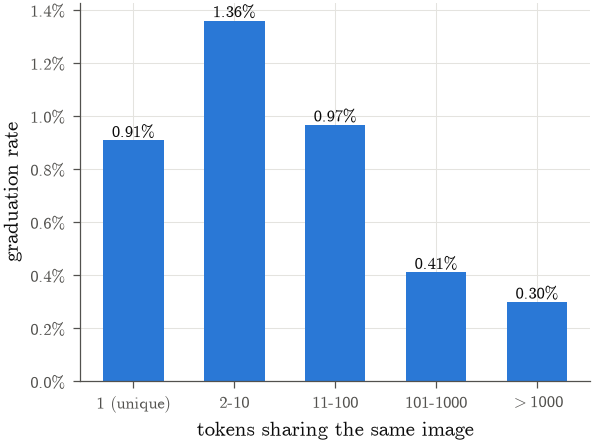

In [27]:
fig, ax = plt.subplots(figsize=FIG_4x3)
ax.bar([tex_escape(b) for b in by_reuse.index.astype(str)], by_reuse["mean"], color=BLUE, width=0.6)
for x, v in enumerate(by_reuse["mean"]):
    ax.text(x, v, pct(v, 2), ha="center", va="bottom", fontsize=8, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_xlabel("tokens sharing the same image")
ax.set_ylabel("graduation rate")
save(fig, "graduation_by_reuse")

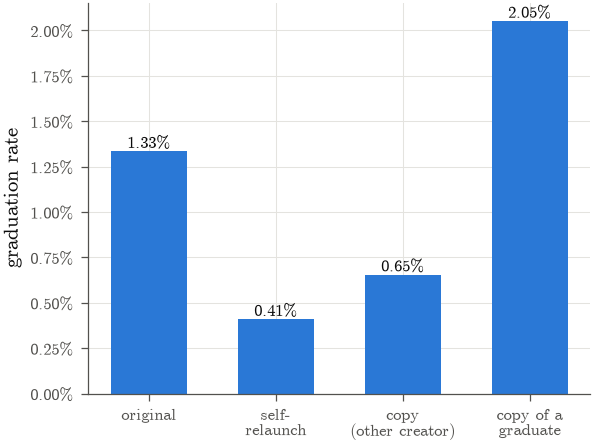

In [28]:
fig, ax = plt.subplots(figsize=FIG_4x3)
labels = ["original", "self-\nrelaunch", "copy\n(other creator)", "copy of a\ngraduate"]
ax.bar(labels, by_role["mean"], color=BLUE, width=0.6)
for x, v in enumerate(by_role["mean"]):
    ax.text(x, v, pct(v, 2), ha="center", va="bottom", fontsize=8, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("graduation rate")
save(fig, "graduation_by_role")

## 5. Visual gallery

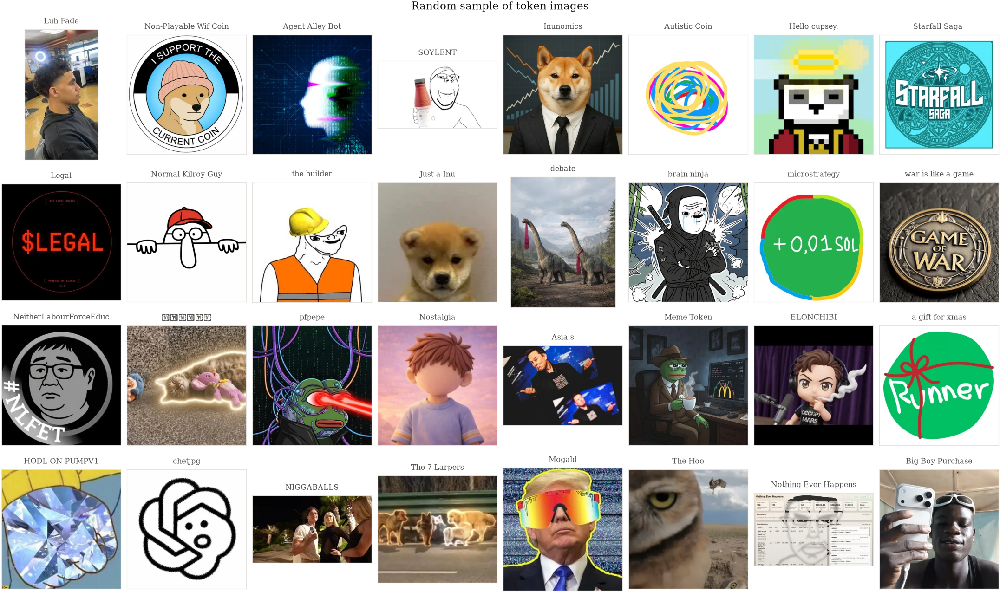

In [29]:
sample = q('''
SELECT i.sha256, m.meta_name
FROM token_images i LEFT JOIN token_metadata m USING (mint)
WHERE i.status = 'ok'
USING SAMPLE 32 ROWS (reservoir, 42)
''')
fig = show_grid(sample.sha256, sample.meta_name.fillna(""), suptitle="Random sample of token images")
save(fig, "gallery_random")

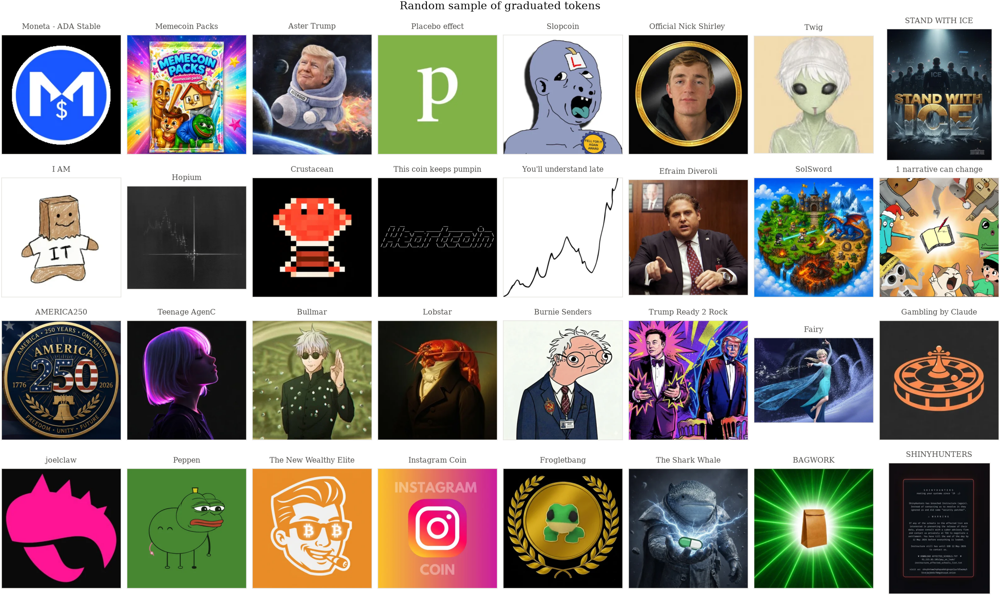

In [30]:
grad_sample = q('''
SELECT i.sha256, m.meta_name
FROM token_images i
JOIN graduations g USING (mint)
LEFT JOIN token_metadata m USING (mint)
WHERE i.status = 'ok'
USING SAMPLE 32 ROWS (reservoir, 42)
''')
fig = show_grid(grad_sample.sha256, grad_sample.meta_name.fillna(""),
                suptitle="Random sample of graduated tokens")
save(fig, "gallery_graduated")

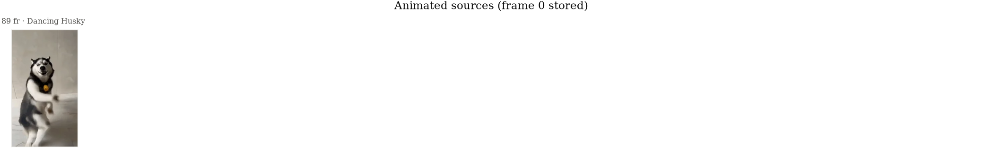

In [31]:
anim_sample = q('''
SELECT i.sha256, m.meta_name, i.n_frames
FROM token_images i LEFT JOIN token_metadata m USING (mint)
WHERE i.status = 'ok' AND i.is_animated
USING SAMPLE 16 ROWS (reservoir, 42)
''')
fig = show_grid(anim_sample.sha256,
                [f"{f} fr · {n}" for f, n in zip(anim_sample.n_frames, anim_sample.meta_name.fillna(""))],
                suptitle="Animated sources (frame 0 stored)")
save(fig, "gallery_animated")

## 6. Pixel-level features and perceptual hashing (sample of shards)

Decoding millions of images is out of scope for exploration, so we read a random subset of **whole
shards** (≈10k distinct images each), in parallel, with `crypto_analysis.image_features`:

- **brightness**: mean of V in HSV, in [0, 1]
- **saturation**: mean of S in HSV
- **colorfulness**: Hasler & Süsstrunk (2003) metric on RGB
- **contrast**: std of grayscale luminance (0–255); near 0 means a blank / solid-colour image
- **pHash**: 64-bit perceptual hash (DCT of a 32×32 grayscale thumbnail), used in 6.2 to find
  *near*-duplicates that `sha256` misses

The stored WebPs are RGB: the crawler flattens transparency when re-encoding, so alpha cannot be
analysed from the blobs. Shards contain distinct images (not tokens), roughly in crawl order, so this
is a sample of *artworks*, not weighted by how many tokens use each one.

In [32]:
N_SHARDS = 12
shard_files = sorted(IMAGES_DIR.glob("shard_*.parquet"))
picked = rng.choice(len(shard_files), size=N_SHARDS, replace=False)
picked_files = [shard_files[k] for k in sorted(picked)]
print("Shards:", [p.name for p in picked_files])

with ProcessPoolExecutor(max_workers=min(N_SHARDS, os.cpu_count() or 1)) as pool:
    results = list(pool.map(shard_features, picked_files))
feat = pd.concat([r[0] for r in results], ignore_index=True)
decode_errors = pd.concat([r[1] for r in results], ignore_index=True)
print(f"{len(feat):,} images, {len(decode_errors)} decode errors")
feat.drop(columns="phash").describe().T

Shards: ['shard_000022.parquet', 'shard_000023.parquet', 'shard_000025.parquet', 'shard_000053.parquet', 'shard_000113.parquet', 'shard_000114.parquet', 'shard_000141.parquet', 'shard_000170.parquet', 'shard_000185.parquet', 'shard_000201.parquet', 'shard_000226.parquet', 'shard_000263.parquet']
120,000 images, 0 decode errors


,count,mean,std,min,25%,50%,75%,max
brightness,120000.0,0.548037,0.247034,0.0,0.369931,0.549995,0.742481,1.000000
saturation,120000.0,0.332780,0.220931,0.0,0.166750,0.310290,0.475391,1.000000
colorfulness,120000.0,49.829518,34.225207,0.0,25.376287,44.580158,69.742832,263.894226
contrast,120000.0,52.179166,18.363159,0.0,40.579049,51.651167,63.232746,124.732689
background_share,120000.0,0.373175,0.267836,0.0,0.152588,0.262939,0.605042,1.000000


Near-blank images (contrast < 5): 0.38%


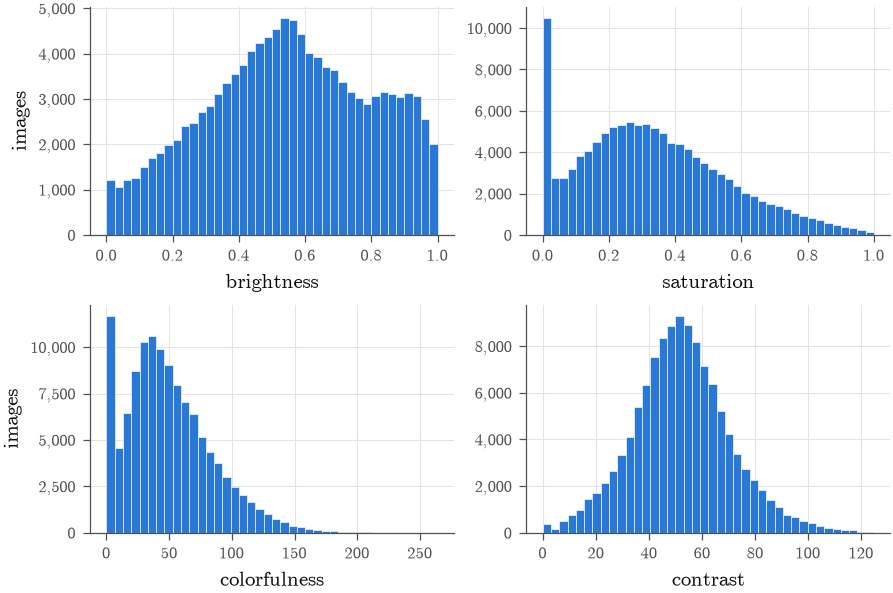

In [33]:
fig, axes = plt.subplots(2, 2, figsize=FIG_6x4)
for ax, col in zip(axes.ravel(), ["brightness", "saturation", "colorfulness", "contrast"]):
    ax.hist(feat[col], bins=40, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.set_xlabel(col)
    ax.yaxis.set_major_formatter(thousands)
for ax in axes[:, 0]:
    ax.set_ylabel("images")
save(fig, "pixel_features")
print(f"Near-blank images (contrast < 5): {(feat.contrast < 5).mean():.2%}")

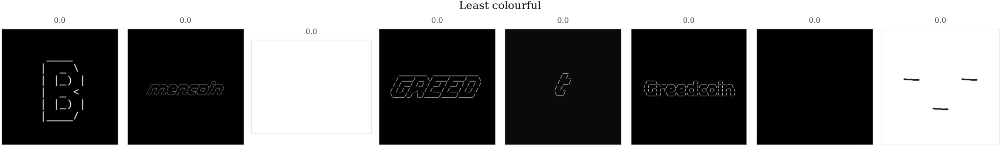

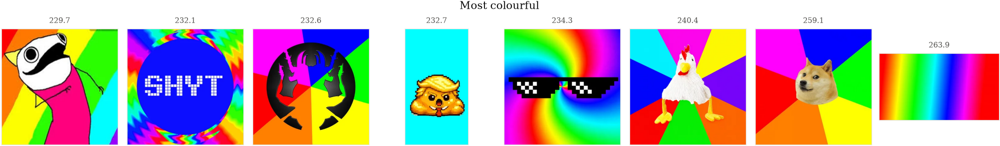

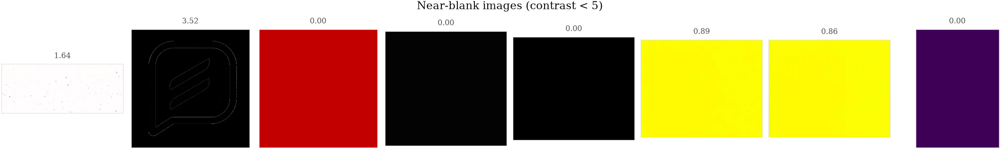

In [34]:
# Extremes: least vs most colourful artworks in the sample
ranked = feat.sort_values("colorfulness")
fig = show_grid(ranked.sha256.head(8), [f"{v:.1f}" for v in ranked.colorfulness.head(8)],
                suptitle="Least colourful")
fig = show_grid(ranked.sha256.tail(8), [f"{v:.1f}" for v in ranked.colorfulness.tail(8)],
                suptitle="Most colourful")
blank = feat[feat.contrast < 5]
if len(blank):
    fig = show_grid(blank.sha256.head(8), [f"{v:.2f}" for v in blank.contrast.head(8)],
                    suptitle="Near-blank images (contrast < 5)")

### 6.1 How far apart are images in pHash space?

Hamming distance between two pHashes = number of differing bits (0–64). Because the hash splits the
DCT coefficients at their median, every hash has ~32 bits set and distances are almost always
**even**. For each image we take the distance to its nearest neighbour in the sample, and keep all
pairs up to `PAIR_MAX_DIST` for calibration and grouping. The search is brute force, about 30 s for
120k images.

188,704 pairs within distance 10


d,0,2,3,4,6,8,9,10
pairs,28821,14499,2,12327,16926,35198,8,80923


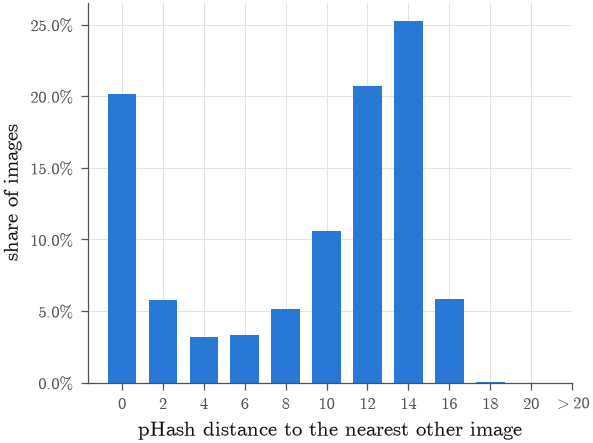

In [35]:
PAIR_MAX_DIST = 10
nn_dist, pairs = hamming_neighbors(feat.phash.to_numpy(), PAIR_MAX_DIST)
feat["nn_dist"] = nn_dist
print(f"{len(pairs):,} pairs within distance {PAIR_MAX_DIST}")
display(pairs.d.value_counts().sort_index().to_frame("pairs").T)

nn_counts = pd.Series(np.minimum(nn_dist, 22)).value_counts(normalize=True).sort_index()
nn_counts = nn_counts[nn_counts.index % 2 == 0]
fig, ax = plt.subplots(figsize=FIG_4x3)
ax.bar(nn_counts.index, nn_counts.values, width=1.4, color=BLUE)
ax.set_xticks(range(0, 23, 2), [str(d) for d in range(0, 22, 2)] + [tex_escape(">20")])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("pHash distance to the nearest other image")
ax.set_ylabel("share of images")
save(fig, "phash_nn_distance")

### 6.2 Calibrating the near-duplicate threshold

Random pairs at each distance (each row: 4 pairs, side by side). Judge by eye where "same artwork"
stops. At small distances pHash matches re-saves, crops and small edits. It is unreliable on
images whose low frequencies are dominated by a plain background:

- **low contrast** (`contrast < LOW_CONTRAST`): dark or washed-out images;
- **flat background** (`background_share ≥ FLAT_BACKGROUND`): a small logo or text on a plain
  backdrop, where the DCT mostly sees the backdrop.

Unrelated images of these kinds get close hashes, so they are left out of the near-duplicate groups.
The second grid shows the same distances with them excluded.

Images excluded from grouping: 9.8%
Share of pairs involving a low-contrast or flat-background image, by distance:


,0,2,4,6,8,10
share,9.9%,16.3%,38.7%,57.5%,70.7%,69.1%


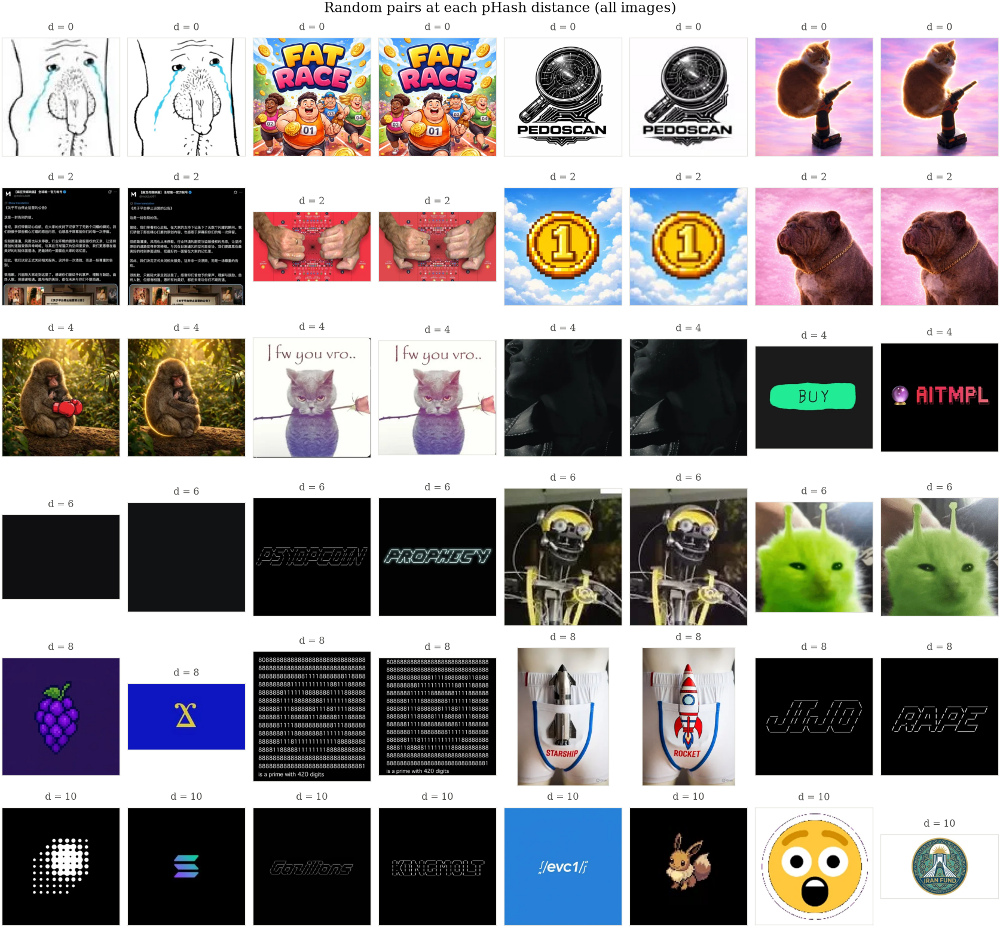

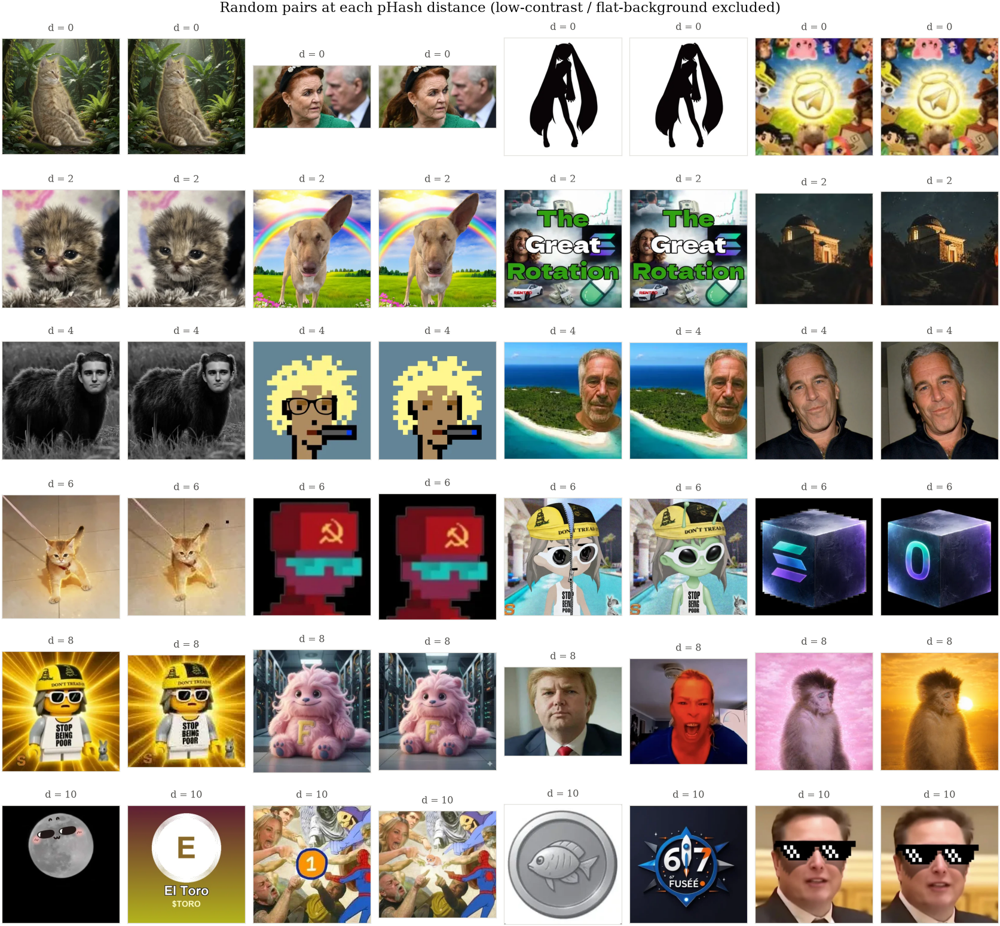

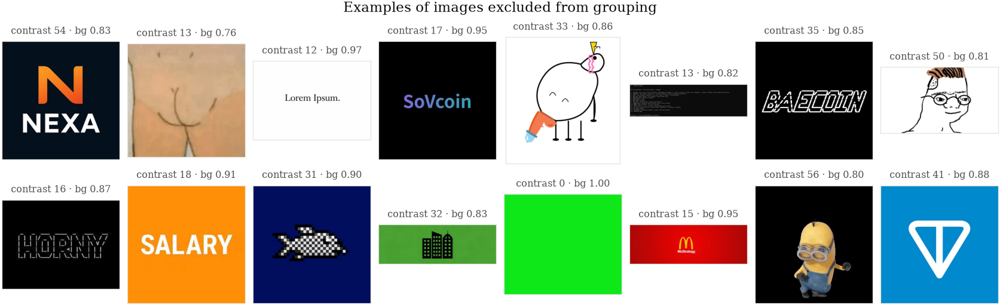

In [36]:
LOW_CONTRAST = 15
FLAT_BACKGROUND = 0.8
reliable = ((feat.contrast >= LOW_CONTRAST) & (feat.background_share < FLAT_BACKGROUND)).to_numpy()
pair_reliable = reliable[pairs.i] & reliable[pairs.j]
print(f"Images excluded from grouping: {1 - reliable.mean():.1%}")


def calibration_grid(candidates, title, per_row=4, seed=SEED):
    shas, titles = [], []
    for d in range(0, PAIR_MAX_DIST + 1, 2):
        at_d = candidates[candidates.d == d]
        chosen = at_d.sample(min(per_row, len(at_d)), random_state=seed)
        for r in chosen.itertuples():
            shas += [feat.sha256[r.i], feat.sha256[r.j]]
            titles += [f"d = {d}"] * 2
        shas += [None] * 2 * (per_row - len(chosen))
        titles += [""] * 2 * (per_row - len(chosen))
    return show_grid(shas, titles, ncols=2 * per_row, size=1.4, suptitle=title)


fig = calibration_grid(pairs, "Random pairs at each pHash distance (all images)")
save(fig, "phash_calibration_all")
fig = calibration_grid(pairs[pair_reliable],
                       "Random pairs at each pHash distance (low-contrast / flat-background excluded)")
save(fig, "phash_calibration_reliable")

unreliable_share = pd.Series(~pair_reliable).groupby(pairs.d.to_numpy()).mean()
print("Share of pairs involving a low-contrast or flat-background image, by distance:")
display(unreliable_share[unreliable_share.index % 2 == 0].map("{:.1%}".format).to_frame("share").T)

excluded = feat[~reliable].sample(16, random_state=SEED)
fig = show_grid(excluded.sha256, [f"contrast {c:.0f} · bg {b:.2f}" for c, b in
                                  zip(excluded.contrast, excluded.background_share)],
                size=1.4, suptitle="Examples of images excluded from grouping")
save(fig, "phash_excluded_examples")

### 6.3 Near-duplicate groups

Images are linked when their pHash distance is at most `PHASH_MAX_DIST` and both are reliable
(see 6.2). Groups are **star clusters** of that graph: the most connected image becomes a centre
and takes all its neighbours, and so on. Every member is within `PHASH_MAX_DIST` of its centre.
Connected components were tried first and rejected: they chain (A≈B≈C≈…) into groups of a hundred
unrelated dark logos, with members 24–32 bits from each other.

In [37]:
PHASH_MAX_DIST = 4
edges = pairs[(pairs.d <= PHASH_MAX_DIST) & pair_reliable]
feat["group"] = star_clusters(len(feat), edges.i, edges.j)  # group id = index of its centre
feat["group_size"] = feat.groupby("group").sha256.transform("size")

# Token counts come from the full ledger: how many tokens use each sampled image
feat = feat.drop(columns="n_tokens", errors="ignore").merge(
    reuse[["sha256", "n_tokens"]], on="sha256", how="left")
feat["n_tokens"] = feat.n_tokens.fillna(1).astype(int)
feat["group_tokens"] = feat.groupby("group").n_tokens.transform("sum")

grouped = feat[feat.group_size > 1]
print(f"Images in the sample:                         {len(feat):,}")
print(f"Images with a near-duplicate (different sha): {len(grouped):,} ({len(grouped) / len(feat):.1%})")
print(f"Near-duplicate groups:                        {grouped.group.nunique():,}")
display(grouped.drop_duplicates("group").group_size.describe().round(1).to_frame("group size").T)

tokens_total = feat.n_tokens.sum()
shared_sha = feat.loc[feat.n_tokens > 1, "n_tokens"].sum() / tokens_total
shared_phash = feat.loc[feat.group_tokens > 1, "n_tokens"].sum() / tokens_total
print(f"Tokens (of the sampled images) whose art is shared, by sha256: {shared_sha:.1%}")
print(f"                                          by pHash group: {shared_phash:.1%}")
print("pHash groups only see near-duplicates inside the sampled shards, so this is a lower bound.")

Images in the sample:                         120,000
Images with a near-duplicate (different sha): 30,242 (25.2%)
Near-duplicate groups:                        10,412


,count,mean,std,min,25%,50%,75%,max
group size,10412.0,2.9,1.9,2.0,2.0,2.0,3.0,31.0


Tokens (of the sampled images) whose art is shared, by sha256: 57.1%
                                          by pHash group: 66.4%
pHash groups only see near-duplicates inside the sampled shards, so this is a lower bound.


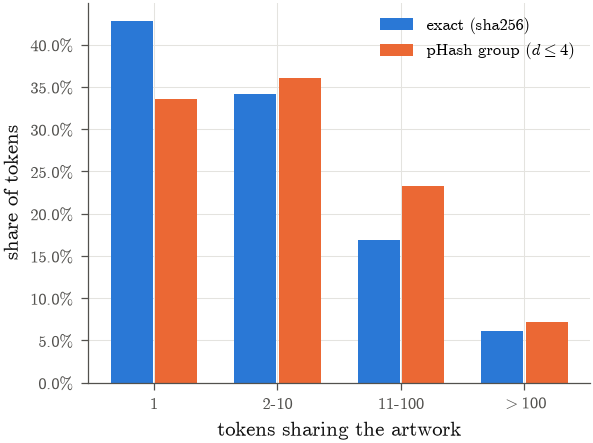

In [38]:
reuse_bins = [0, 1, 10, 100, np.inf]
reuse_labels = ["1", "2-10", "11-100", ">100"]
by_sha = feat.groupby(pd.cut(feat.n_tokens, reuse_bins, labels=reuse_labels), observed=False).n_tokens.sum()
by_grp = feat.groupby(pd.cut(feat.group_tokens, reuse_bins, labels=reuse_labels), observed=False).n_tokens.sum()

fig, ax = plt.subplots(figsize=FIG_4x3)
x = np.arange(len(reuse_labels))
ax.bar(x - 0.18, by_sha / tokens_total, width=0.34, color=BLUE, label="exact (sha256)")
ax.bar(x + 0.18, by_grp / tokens_total, width=0.34, color=ORANGE, label=rf"pHash group ($d \leq {PHASH_MAX_DIST}$)")
ax.set_xticks(x, [tex_escape(lbl) for lbl in reuse_labels])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("tokens sharing the artwork")
ax.set_ylabel("share of tokens")
ax.legend()
save(fig, "phash_vs_sha_reuse")

In [39]:
# Same artwork, same name? Recycled art under one name points to relaunches, while the same art
# under many names points to copycats.
grouped = grouped.assign(name=grouped.sha256.map(names_for(grouped.sha256)))
name_div = grouped.groupby("group").agg(size=("sha256", "size"), names=("name", "nunique"))
print(f"Groups whose images all carry the same top name: {(name_div.names == 1).mean():.1%}")
print(f"Groups with a different name for every image:   {(name_div.names == name_div['size']).mean():.1%}")

Groups whose images all carry the same top name: 41.4%
Groups with a different name for every image:   37.4%


### 6.4 Near-duplicate gallery

One row per group, up to 8 images each, starting with the group's centre. Captions give the pHash
distance to the centre and the most common token name of that image.

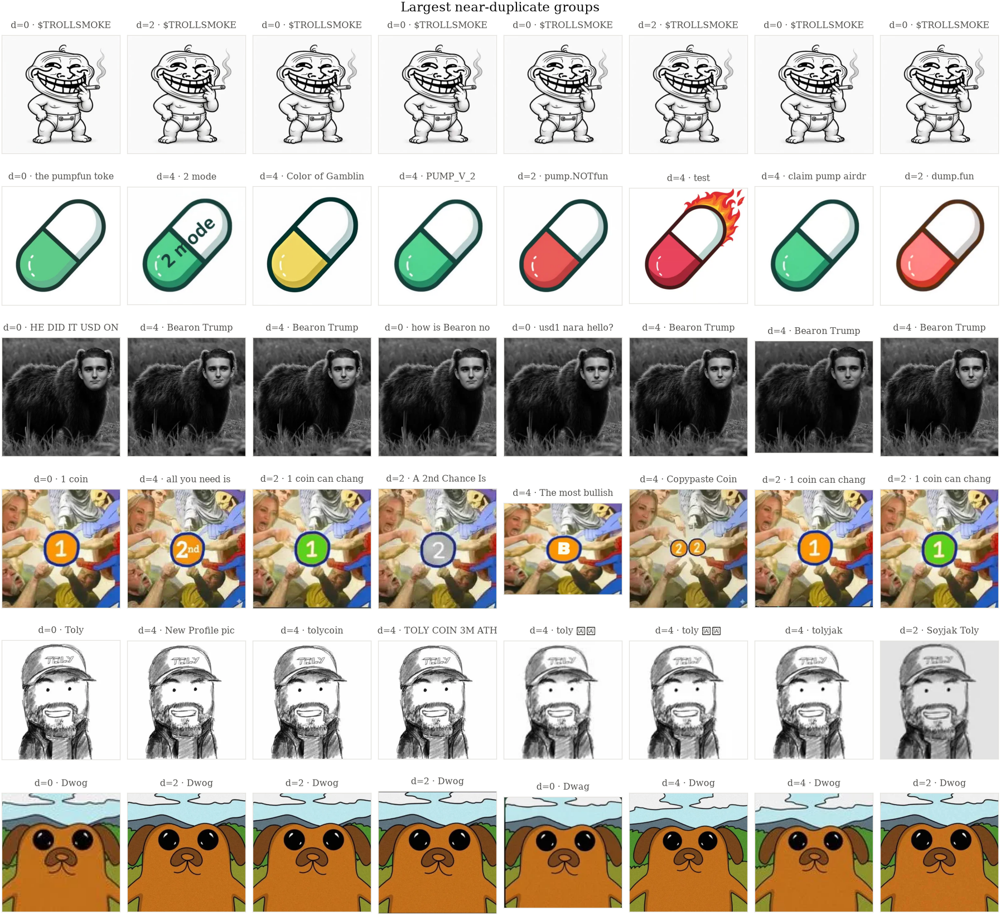

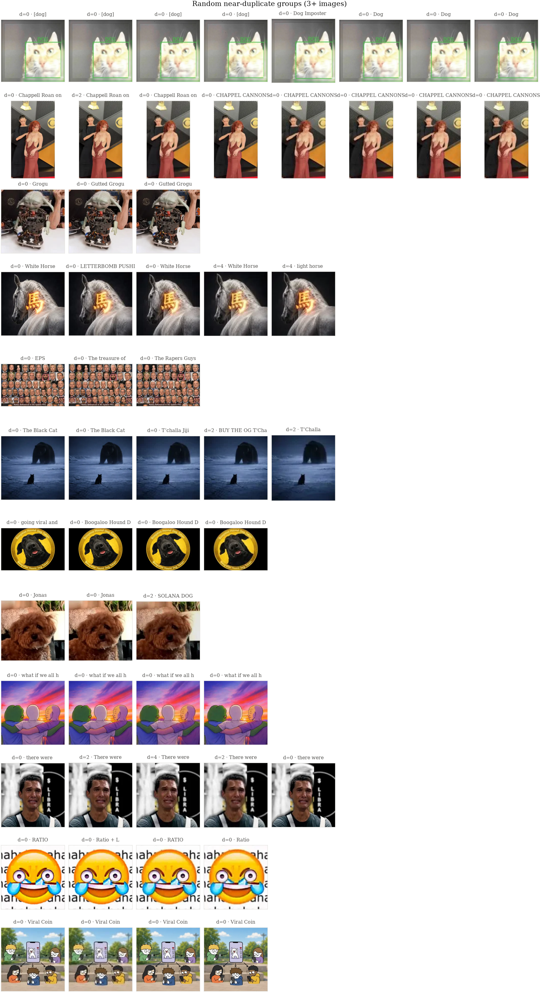

In [40]:
def group_gallery(group_ids, title, per_row=8):
    shas, titles = [], []
    for gid in group_ids:
        members = grouped[grouped.group == gid]
        members = pd.concat([members.loc[[gid]], members.drop(index=gid)]).head(per_row)  # centre first
        dists = np.bitwise_count(members.phash.to_numpy() ^ members.phash.loc[gid])
        for r, d in zip(members.itertuples(), dists):
            shas.append(r.sha256)
            titles.append(f"d={d} · {r.name}")
        shas += [None] * (per_row - len(members))
        titles += [""] * (per_row - len(members))
    return show_grid(shas, titles, ncols=per_row, size=1.5, suptitle=title)


largest = name_div.sort_values("size", ascending=False).index[:6]
fig = group_gallery(largest, "Largest near-duplicate groups")
save(fig, "phash_groups_largest")

candidates = name_div[(name_div["size"] >= 3)].index.to_numpy()
random_groups = rng.choice(candidates, size=min(12, len(candidates)), replace=False)
fig = group_gallery(random_groups, "Random near-duplicate groups (3+ images)")
save(fig, "phash_groups_random")

## 7. Takeaways and next steps

Numbers below are from the run on 2026-10-16 (image crawl covering 2025-10-26 → 2026-07-10);
re-check them as the crawl advances. The pHash numbers come from a random sample of 12 shards.

**Coverage.** 5.21M tokens have an image ledger row and 98.6% of them were stored successfully.
Failures are concentrated on non-IPFS hosts (`image.solanatracker.io`, `pbs.twimg.com`,
`storage.googleapis.com`), plus `decode_error` from `ipfs.io` (non-image payloads). Tokens launched
after 2026-07-10 have no ledger rows yet (6.57M tokens in total).

**Source files.** JPEG 48%, PNG 34%, WebP 17%, GIF <1%. Square images dominate (512², 400², 1024²);
most sources are larger than the stored 384px. Under 1% of sources are animated, and only frame 0 is kept.

**Reuse is the headline.** 5.14M tokens use only 2.70M distinct images: **59% of tokens share
byte-identical artwork** with at least one other token, and ~7% share it with more than 100 others.
Ordered by launch time, 46.7% of tokens are **copies** of an earlier token's image; 18.2% are
**self-relaunches** (same creator as the original) and 4.4% copy the image of a token that had
already **graduated**. Daily, the share of copies rises from ~20–30% (Nov 2025) to ~60% (Jun 2026),
with the largest shift around 2026-04-06 (checkpoint R: 45% → 53%). The most reused images are
meme templates, blank/black squares and the Solana logo. Some copycat waves are single-day bot
bursts (W1: 924 launches of one image in a day).

**Copying winners.** Copies of a graduate arrive fast: 10% within 4 minutes of the graduation and
half within ~14 hours, with a second mode around days to weeks. The most-copied graduates
(KILLME, banana dad, METH DAMON, 50) drew 2.5–3.2k copies each, clustered in Apr–Jun 2026.

**Outcome.** Graduation is rare (~1%), and spiked on 2026-03-12/19 and 2026-06-30 (S1–S4), when the
daily rate rose from ~1% to 2–4%. By role: originals graduate at 1.33%, self-relaunches at 0.41% and
other copies at 0.65%. **Copies of a graduate graduate at 2.05%**, the highest of any group: chasing
a winner's image works more often than launching unrelated copies. This is descriptive only, since
copies of graduates are concentrated in the high-graduation periods. Animated sources graduate ~2×
more often (2.0% vs 1.0%).

**Near-duplicates (pHash, 120k-image sample).** With distance ≤ 4, star clustering and
low-contrast / flat-background images excluded (9.8%), 25% of images have a near-duplicate under a
different `sha256`. Counting near-duplicates raises the share of tokens with shared art from 57%
to at least 66% (a lower bound: groups only see the sampled shards). The groups are re-saves,
recolours and **template variants** (the same pill or numbered-coin meme in different colours), a
kind of copycatting exact hashing cannot see. 41% of groups keep one name (relaunches) and 38%
carry a different name per image (copycats). pHash is not reliable on simple logos over flat
backgrounds, which is why those are excluded.

**Next steps for the taxonomy work:**

- **Image embeddings** (e.g. CLIP / SigLIP) over the 2.7M distinct images, then clustering: visual
  themes (animals, memes, celebrities, AI art, text-only logos…) to cross with text-based categories.
- **pHash for all 2.7M images** (`shard_features` over all 270 shards ≈ 15 min on 16 cores), stored
  as a table, with multi-index hashing (split the 64 bits into chunks) instead of brute force to find
  pairs across the whole dataset, plus a second signal (e.g. CLIP) for flat-background logos.
- **Reuse features**: first-use vs copy, number of distinct creators per image (`tokens.coin_creator`),
  time between first and later use, to separate organic meme waves from bot farms.
- **Image–text consistency**: CLIP similarity between the image and `meta_name` / `description`.